<a href="https://colab.research.google.com/github/gpugovka/ML-stuff/blob/main/HW_Concrete_Compressive_Strength_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Homework – Concrete Compressive Strength Regression**

## Overview

In this homework, you will apply the regression concepts covered in class to a new dataset: the **UCI Concrete Compressive Strength Dataset**.

The goal is to predict **concrete compressive strength (MPa)** from the ingredients and age of a concrete mixture.

You will practice:

- Data loading and understanding
- Separating features and target
- Train/test split
- Linear Regression
- `SGDRegressor`
- Regression evaluation metrics
- Feature scaling with `StandardScaler`
- Data leakage
- 5-fold cross-validation
- Polynomial Regression
- Model complexity
- Bias–variance tradeoff
- Model selection
- Saving and loading a model with `joblib`
- Making a prediction on unseen data

**Important:** Complete all questions and include short written explanations where requested.

## **Dataset Information**

The dataset contains **1,030 observations**, **8 quantitative input variables**, and **1 quantitative target variable**.

### Features

| Feature | Description |
|---|---|
| Cement | Cement amount (kg/m³) |
| Blast Furnace Slag | Blast furnace slag amount (kg/m³) |
| Fly Ash | Fly ash amount (kg/m³) |
| Water | Water amount (kg/m³) |
| Superplasticizer | Superplasticizer amount (kg/m³) |
| Coarse Aggregate | Coarse aggregate amount (kg/m³) |
| Fine Aggregate | Fine aggregate amount (kg/m³) |
| Age | Age of concrete (days) |

### Target

**Concrete compressive strength (MPa)**

The dataset is from the UCI Machine Learning Repository.

## **Part 1 – Data Loading, Understanding, and Initial EDA**

Load the Concrete Compressive Strength dataset.

First, inspect the dataset by displaying:

- the shape of the dataset
- the column names
- the first five rows
- the data types
- descriptive statistics

### **Missing Values**

Check whether the dataset contains missing values.



### **Short Exploratory Data Analysis (EDA)**

You are already familiar with basic EDA from class. Perform a **short EDA** to better understand this regression dataset.

Create **at least 3 meaningful visualizations**. You may choose appropriate plots such as:

- histograms/distribution plots
- boxplots
- scatter plots between predictors and compressive strength
- a correlation heatmap
- other appropriate visualizations you learned in class

Your plots should help you understand the variables and their potential relationship with the target variable.

**Important:** Do not create plots simply for the sake of creating plots. For each visualization, briefly explain what it tells you about the data.


In [1]:
# Perform the initial data inspection.
# Write your code here.
import pandas as pd

concrete_ds = pd.read_csv("concrete_data.csv")
concrete_ds

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


In [4]:
# Check for missing values and perform a short EDA.
concrete_ds.info()
concrete_ds.isna().count()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   cement                         1030 non-null   float64
 1   blast_furnace_slag             1030 non-null   float64
 2   fly_ash                        1030 non-null   float64
 3   water                          1030 non-null   float64
 4   superplasticizer               1030 non-null   float64
 5   coarse_aggregate               1030 non-null   float64
 6   fine_aggregate                 1030 non-null   float64
 7   age                            1030 non-null   int64  
 8   concrete_compressive_strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


,0
cement,1030
blast_furnace_slag,1030
fly_ash,1030
water,1030
superplasticizer,1030
coarse_aggregate,1030
fine_aggregate,1030
age,1030
concrete_compressive_strength,1030


/tmp/ipykernel_6467/1868580969.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


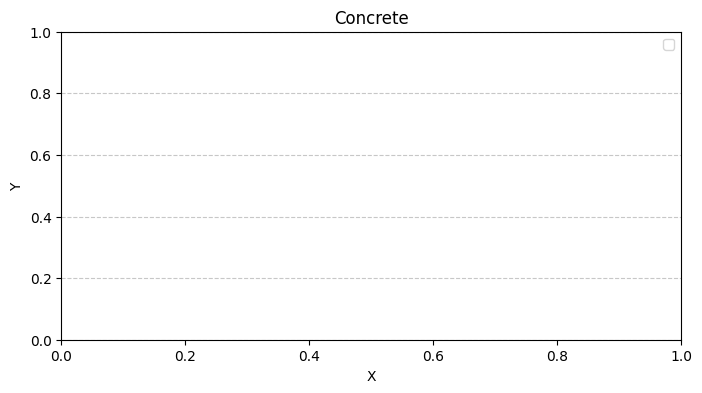

In [7]:
# Create at least 3 meaningful visualizations and briefly interpret your findings.
# Write your code here.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
# species_list = penguins["species"].unique()
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

# for sp, col in zip(species_list, colors):
#     subset = penguins[penguins["species"] == sp]["flipper_length_mm"]
#     ax.hist(subset, bins=15, alpha=0.6, label=sp, color=col, edgecolor="black")

ax.set_title("Concrete")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

### **Question 1 – Missing Values**

Does the dataset contain any missing values?

If yes, identify the variables and the number of missing values.
If no, clearly state that there are no missing values.

### **Question 2 – Exploratory Data Analysis**

Based on your descriptive statistics and visualizations, describe **at least three specific observations** about the dataset.

Your observations should be supported by your EDA.


**Your Answer:**

Q1 No, the dataset does not contain any missing values.


### **Question 3**

How many observations and predictor variables are in the dataset?

Which column is the target variable?


**Your Answer:**

## **Part 2 – Data Preparation**

Separate the features (`X`) and target (`y`).

Then split the dataset into training and testing sets.

Use:

- `test_size=0.2`
- `random_state=42`

Display the shapes of the training and testing sets.

In [14]:
# Write your code here
from sklearn.model_selection import train_test_split

X = concrete_ds.drop(columns=["concrete_compressive_strength"])
y = concrete_ds["concrete_compressive_strength"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state = 13)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((721, 8), (309, 8), (721,), (309,))

In [ ]:
# Write your code here

## **Part 3 – Multiple Linear Regression**

Train a `LinearRegression` model using the training data.

Predict the target values for the test set.

Calculate and report:

- MAE
- MSE
- RMSE
- R²

In [21]:
# Write your code here
from sklearn.linear_model import LinearRegression
import numpy as np

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
MAE = (y_pred-y_test).mean()
MSE = abs(y_pred ** 2 - y_test ** 2).mean()
RMSE = np.sqrt(MSE)
MAE, MSE, RMSE

(np.float64(-0.4184064347541799),
 np.float64(671.7350657645737),
 np.float64(25.917852259872415))

In [ ]:
# Write your code here

### **Question 4**

Based on the four evaluation metrics, how well does the Multiple Linear Regression model perform?

Briefly explain what RMSE and R² tell you about the model.

**Your Answer:**

## **Part 4 – Gradient Descent Regression**

Train an `SGDRegressor` using the following parameters:

```python
max_iter=1000
tol=1e-3
random_state=42
```

First, train the model using the **unscaled** training data.

Predict the test set and calculate:

- MAE
- MSE
- RMSE
- R²

In [ ]:
# Write your code here

In [ ]:
# Write your code here

### **Question 5**

Compare the SGD results with Multiple Linear Regression.

Do you notice anything unusual about the unscaled `SGDRegressor` results?

Why might this happen?

**Your Answer:**

## **Part 5 – Feature Scaling**

Use `StandardScaler` to standardize the features.

**Important:** Fit the scaler using only the training data.

Then transform both the training and testing data.

Display the mean and standard deviation of the scaled training data.

In [ ]:
# Write your code here

In [ ]:
# Write your code here

### **Question 6 – Data Leakage**

Should the scaler be fit before or after the train-test split?

Explain why.

**Your Answer:**

### **Scaled SGDRegressor**

Train the same `SGDRegressor` using the scaled training data.

Predict the test set and calculate:

- MAE
- MSE
- RMSE
- R²

Then compare the scaled and unscaled SGD models.

In [ ]:
# Write your code here

In [ ]:
# Write your code here

### **Question 7**

Why did feature scaling affect `SGDRegressor` much more than ordinary `LinearRegression`?

Explain in your own words.

**Your Answer:**

## **Part 6 – 5-Fold Cross-Validation**

Use **5-fold cross-validation** with `LinearRegression`.

Calculate the **MSE** for each fold and convert the values to **RMSE**.

Report:

- RMSE for each fold
- mean RMSE
- standard deviation of RMSE

In [ ]:
# Write your code here

### **Question 8**

What does the standard deviation of the cross-validation RMSE values tell you about model performance?

Is the model performance relatively consistent across the five folds?

**Your Answer:**

## **Part 7 – Polynomial Regression**

The UCI documentation describes concrete compressive strength as a **highly nonlinear function of age and ingredients**.

Use `PolynomialFeatures` and `LinearRegression` to investigate whether increasing model complexity improves prediction.

Test the following polynomial degrees:

- Degree 1
- Degree 2
- Degree 3
- Degree 4

For each degree:

1. Transform the training and testing features.
2. Train a `LinearRegression` model.
3. Calculate training RMSE.
4. Calculate testing RMSE.
5. Calculate training R².
6. Calculate testing R².

Create a table containing all results.

In [ ]:
# Write your code here

In [ ]:
# Write your code here

### **Question 9**

What happens to training error as polynomial degree increases?

What happens to testing error?

Describe the pattern you observe.

**Your Answer:**

### **Question 10 – Bias–Variance Tradeoff**

Using your results, identify:

- a degree that appears to underfit
- a degree that gives a good balance between training and testing performance
- a degree that appears to overfit, if one is observed

Explain your reasoning.

**Your Answer:**

### **Question 11 – Model Selection**

Based on the **testing RMSE**, which polynomial degree would you select as your final model?

Explain why you selected it.

Do **not** choose the degree based only on training RMSE or training R².

**Your Answer:**

## **Part 8 – Final Model**

Using the polynomial degree you selected, train a final model using the original train/test split.

Report:

- selected polynomial degree
- test RMSE
- test R²

In [ ]:
# Write your code here

## **Part 9 – Model Deployment**

Retrain your selected polynomial model on the **entire dataset** so that it can be prepared for deployment.

Save:

- the polynomial converter as `concrete_poly_converter.joblib`
- the trained regression model as `final_concrete_model.joblib`

Then reload both objects to demonstrate that they can be used after saving.

In [ ]:
# Write your code here

### **Question 12 – Prediction on Unseen Data**

Use your saved model to predict the compressive strength for this **new concrete mixture**:

| Feature | Value |
|---|---:|
| Cement | 300 |
| Blast Furnace Slag | 100 |
| Fly Ash | 50 |
| Water | 180 |
| Superplasticizer | 10 |
| Coarse Aggregate | 1000 |
| Fine Aggregate | 750 |
| Age | 28 |

Create a DataFrame with these values, transform it using your saved polynomial converter, and use your saved model to make the prediction.

Report the predicted compressive strength in **MPa**.

In [ ]:
# Write your code here

## **Final Reflection**

### **Question 13**

Answer the following briefly:

1. Why is scaling important for `SGDRegressor`?
2. Why must the scaler be fitted only on training data?
3. Why can a high-degree polynomial model overfit?
4. Why should model selection be based on test/validation performance rather than training performance?
5. What is the main advantage of cross-validation?

**Your Answers:**